### 06 checking predictions (edge hiding model, ckpt/best.pt)
reads: prep/, ckpt/best.pt, name columns from the csvs  
writes: results/check_score_dist.png, novel_ct_top200.csv, novel_ht_top200.csv

#### setup

In [1]:
import os, json, numpy as np, pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

DATA = 'C:/Users/Nimishavarma/OneDrive/Dokumenty'
PREP = 'C:/Users/Nimishavarma/OneDrive/Dokumenty/hti-project/prep'
CKPT = 'C:/Users/Nimishavarma/OneDrive/Dokumenty/hti-project/ckpt'
OUT  = 'C:/Users/Nimishavarma/OneDrive/Dokumenty/hti-project/results'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#### load data + readable names

In [2]:
meta = json.load(open(f'{PREP}/meta.json'))
n_h, n_c, n_t = meta['n_h'], meta['n_c'], meta['n_t']
C_feat = torch.from_numpy(np.load(f'{PREP}/C_feat.npy')).to(device)
T_feat = torch.from_numpy(np.load(f'{PREP}/T_feat.npy')).to(device)
hc = np.load(f'{PREP}/hc_edges.npy')
ct_tr = np.load(f'{PREP}/ct_train.npy')
ct_vp = np.load(f'{PREP}/ct_val_pos.npy')
ct_tp = np.load(f'{PREP}/ct_test_pos.npy')
ct_tn = np.load(f'{PREP}/ct_test_neg.npy')

idm = json.load(open(f'{PREP}/id_maps.json'))
i2h = {v: k for k, v in idm['h2i'].items()}
i2c = {v: k for k, v in idm['c2i'].items()}
i2t = {v: k for k, v in idm['t2i'].items()}

tinfo = pd.read_csv(f'{DATA}/target_features_aac.csv', usecols=['protein_id','protein_name'])
sym = pd.read_csv(f'{DATA}/compound_target_labeled.csv', usecols=['protein_id','hgnc_symbol']).drop_duplicates('protein_id')
tinfo = tinfo.merge(sym, on='protein_id', how='left').set_index('protein_id')
hname = pd.read_csv(f'{DATA}/herb_compound_edges.csv', sep='\t', usecols=['herb_id','botanical_name'])
hname = hname.drop_duplicates('herb_id').set_index('herb_id')['botanical_name']

#### model classes

In [3]:
class RelConv(nn.Module):
    def __init__(self, in_dim, out_dim, n_rel):
        super().__init__()
        self.W_rel  = nn.Parameter(torch.randn(n_rel, in_dim, out_dim) * 0.01)
        self.W_self = nn.Parameter(torch.randn(in_dim, out_dim) * 0.01)
        self.bias   = nn.Parameter(torch.zeros(out_dim))
    def forward(self, x, edge_sets):
        out = x @ self.W_self
        for r, (src, dst) in enumerate(edge_sets):
            if src.numel() == 0: continue
            m = x[src] @ self.W_rel[r]
            agg = torch.zeros(x.size(0), out.size(1), device=x.device, dtype=out.dtype)
            agg.index_add_(0, dst, m)
            deg = torch.zeros(x.size(0), device=x.device)
            deg.index_add_(0, dst, torch.ones_like(dst, dtype=torch.float))
            out = out + agg / deg.clamp(min=1).unsqueeze(1)
        return out + self.bias

class Encoder(nn.Module):
    def __init__(self, n_h, n_c, n_t, d_in_c, d_in_t, d=128, n_rel=4, dropout=0.2):
        super().__init__()
        self.herb_emb = nn.Embedding(n_h, d)
        self.proj_c = nn.Linear(d_in_c, d)
        self.proj_t = nn.Linear(d_in_t, d)
        self.l1 = RelConv(d, d, n_rel)
        self.l2 = RelConv(d, d, n_rel)
        self.drop = nn.Dropout(dropout)
        self.n_h, self.n_c, self.n_t = n_h, n_c, n_t
    def project(self, Cf, Tf):
        return torch.cat([self.herb_emb.weight, F.relu(self.proj_c(Cf)), F.relu(self.proj_t(Tf))], dim=0)
    def forward(self, Cf, Tf, edge_sets):
        x = self.project(Cf, Tf)
        x = F.relu(self.l1(x, edge_sets))
        x = self.drop(x)
        return self.l2(x, edge_sets)

class DistMult(nn.Module):
    def __init__(self, d, n_rel=1):
        super().__init__()
        self.rel = nn.Parameter(torch.randn(n_rel, d) * 0.01)
    def forward(self, hs, ht, r=0):
        return (hs * self.rel[r] * ht).sum(dim=-1)

class Model(nn.Module):
    def __init__(self, n_h, n_c, n_t, d_in_c, d_in_t, d=128):
        super().__init__()
        self.enc = Encoder(n_h, n_c, n_t, d_in_c, d_in_t, d=d, n_rel=4)
        self.dec = DistMult(d, n_rel=1)
    def encode(self, Cf, Tf, esets):
        return self.enc(Cf, Tf, esets)
    def score_ct(self, Z, c_idx, t_idx):
        return self.dec(Z[self.enc.n_h + c_idx], Z[self.enc.n_h + self.enc.n_c + t_idx])
    def scores_all(self, Z):
        n_h, n_c = self.enc.n_h, self.enc.n_c
        return (Z[n_h:n_h+n_c] * self.dec.rel[0]) @ Z[n_h+n_c:].t()

#### score every compound-target pair

In [4]:
model = Model(n_h, n_c, n_t, C_feat.shape[1], T_feat.shape[1], d=128).to(device)
model.load_state_dict(torch.load(f'{CKPT}/best.pt', map_location=device))
model.eval()

h = torch.from_numpy(hc[0]).long().to(device)
c = torch.from_numpy(hc[1] + n_h).long().to(device)
cc = torch.from_numpy(ct_tr[0] + n_h).long().to(device)
tt = torch.from_numpy(ct_tr[1] + n_h + n_c).long().to(device)
esets = [(h, c), (c, h), (cc, tt), (tt, cc)]

with torch.no_grad():
    Z = model.encode(C_feat, T_feat, esets)
    S = model.scores_all(Z).cpu().numpy()

# 0 unlabeled, 1 train, 2 val, 3 test
status = np.zeros((n_c, n_t), dtype=np.int8)
status[ct_tr[0], ct_tr[1]] = 1
status[ct_vp[0], ct_vp[1]] = 2
status[ct_tp[0], ct_tp[1]] = 3
lab = np.array(['unlabeled', 'train', 'val', 'TEST HIT'])
print(S.shape)

(2319, 1341)


#### check 1: score distributions

mean score  train pos 1.974  test pos 0.791  test neg -4.917
test positives above 95th pct of negatives: 40.7%  (random would be 5%)


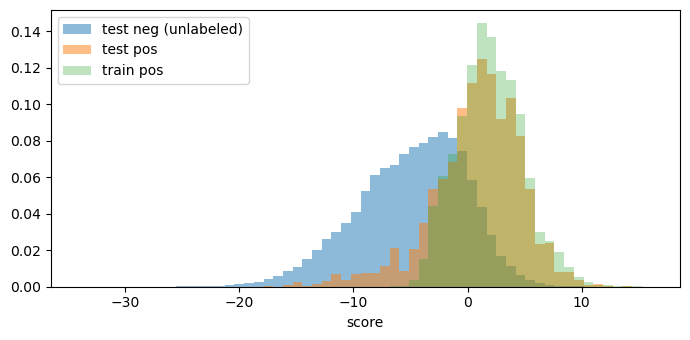

In [5]:
# 1. score distributions: test positives should sit clearly above the sampled negatives
s_tr = S[ct_tr[0], ct_tr[1]]
s_tp = S[ct_tp[0], ct_tp[1]]
s_tn = S[ct_tn[0], ct_tn[1]]
thr = np.percentile(s_tn, 95)
print('mean score  train pos %.3f  test pos %.3f  test neg %.3f' % (s_tr.mean(), s_tp.mean(), s_tn.mean()))
print('test positives above 95th pct of negatives: %.1f%%  (random would be 5%%)' % (100 * (s_tp > thr).mean()))

plt.figure(figsize=(7, 3.5))
bins = np.linspace(min(s_tn.min(), s_tp.min()), max(s_tr.max(), s_tp.max()), 60)
plt.hist(s_tn, bins, alpha=0.5, density=True, label='test neg (unlabeled)')
plt.hist(s_tp, bins, alpha=0.5, density=True, label='test pos')
plt.hist(s_tr, bins, alpha=0.3, density=True, label='train pos')
plt.xlabel('score')
plt.legend()
plt.tight_layout()
plt.savefig(f'{OUT}/check_score_dist.png', dpi=120)
plt.show()

#### check 2: precision@10 per test compound

In [6]:
# 2. precision@10 per test compound, train/val targets removed from the candidate list
p10, rnd = [], []
for cmp in np.unique(ct_tp[0]):
    s = S[cmp].copy()
    s[(status[cmp] == 1) | (status[cmp] == 2)] = -np.inf
    top = np.argsort(-s)[:10]
    p10.append((status[cmp, top] == 3).mean())
    n_cand = np.isfinite(s).sum()
    rnd.append((status[cmp] == 3).sum() / n_cand)
print('test compounds:', len(p10))
print('precision@10 model  %.4f' % np.mean(p10))
print('precision@10 random %.4f' % np.mean(rnd))
print('compounds with at least 1 hit in top 10: %.1f%%' % (100 * np.mean(np.array(p10) > 0)))

test compounds: 415
precision@10 model  0.1205
precision@10 random 0.0041
compounds with at least 1 hit in top 10: 43.4%


#### check 3: top 10 targets for example compounds

In [7]:
def top_targets(cmp, k=10):
    s = S[cmp].copy()
    s[status[cmp] == 1] = -np.inf
    idx = np.argsort(-s)[:k]
    pids = [i2t[i] for i in idx]
    return pd.DataFrame({
        'rank': np.arange(1, k + 1),
        'protein_id': pids,
        'symbol': tinfo.loc[pids, 'hgnc_symbol'].values,
        'protein_name': tinfo.loc[pids, 'protein_name'].values,
        'score': s[idx].round(3),
        'status': lab[status[cmp, idx]],
    })

# 3. a few test compounds with the most held-out targets
cnt = pd.Series(ct_tp[0]).value_counts()
for cmp in cnt.index[:3]:
    print(i2c[cmp], '| train targets', (status[cmp] == 1).sum(), '| held-out test targets', cnt[cmp])
    display(top_targets(cmp))

IMPPAT3_PHYID000007 | train targets 246 | held-out test targets 50


,rank,protein_id,symbol,protein_name,score,status
0,1,UNIPROT:P11509,CYP2A6,Cytochrome P450 2A6,-2.004,unlabeled
1,2,UNIPROT:P17252,PRKCA,Protein kinase C alpha type,-2.028,TEST HIT
2,3,UNIPROT:P48730,CSNK1D,Casein kinase I isoform delta,-2.045,unlabeled
3,4,UNIPROT:P03372,ESR1,Estrogen receptor,-2.048,TEST HIT
4,5,UNIPROT:P21728,DRD1,Dopamine receptor D1,-2.078,val
5,6,UNIPROT:P35372,OPRM1,Mu-type opioid receptor,-2.082,val
6,7,UNIPROT:P33261,CYP2C19,Cytochrome P450 2C19,-2.118,val
7,8,UNIPROT:Q12809,KCNH2,Voltage-gated inwardly rectifying potassium ch...,-2.159,TEST HIT
8,9,UNIPROT:Q16539,MAPK14,Mitogen-activated protein kinase 14,-2.170,TEST HIT
9,10,UNIPROT:P47869,GABRA2,Gamma-aminobutyric acid receptor subunit alpha-2,-2.246,unlabeled


IMPPAT3_PHYID000156 | train targets 193 | held-out test targets 39


,rank,protein_id,symbol,protein_name,score,status
0,1,UNIPROT:Q99928,GABRG3,Gamma-aminobutyric acid receptor subunit gamma-3,-1.771,TEST HIT
1,2,UNIPROT:P17252,PRKCA,Protein kinase C alpha type,-2.016,TEST HIT
2,3,UNIPROT:P24941,CDK2,Cyclin-dependent kinase 2,-2.019,val
3,4,UNIPROT:P11309,PIM1,Serine/threonine-protein kinase pim-1,-2.082,val
4,5,UNIPROT:O43451,MGAM,Maltase-glucoamylase,-2.149,unlabeled
5,6,UNIPROT:P21802,FGFR2,Fibroblast growth factor receptor 2,-2.172,unlabeled
6,7,UNIPROT:P31751,AKT2,RAC-beta serine/threonine-protein kinase,-2.231,unlabeled
7,8,UNIPROT:O14920,IKBKB,Inhibitor of nuclear factor kappa-B kinase sub...,-2.255,unlabeled
8,9,UNIPROT:P48169,GABRA4,Gamma-aminobutyric acid receptor subunit alpha-4,-2.279,TEST HIT
9,10,UNIPROT:P04798,CYP1A1,Cytochrome P450 1A1,-2.302,val


IMPPAT3_PHYID001768 | train targets 190 | held-out test targets 35


,rank,protein_id,symbol,protein_name,score,status
0,1,UNIPROT:P49286,MTNR1B,Melatonin receptor type 1B,-0.622,unlabeled
1,2,UNIPROT:P17252,PRKCA,Protein kinase C alpha type,-0.677,TEST HIT
2,3,UNIPROT:P48730,CSNK1D,Casein kinase I isoform delta,-0.759,unlabeled
3,4,UNIPROT:P11509,CYP2A6,Cytochrome P450 2A6,-0.873,TEST HIT
4,5,UNIPROT:P42226,STAT6,Signal transducer and activator of transcripti...,-0.896,unlabeled
5,6,UNIPROT:P47869,GABRA2,Gamma-aminobutyric acid receptor subunit alpha-2,-0.923,unlabeled
6,7,UNIPROT:P45984,MAPK9,Mitogen-activated protein kinase 9,-0.964,unlabeled
7,8,UNIPROT:P04150,NR3C1,Glucocorticoid receptor,-1.093,val
8,9,UNIPROT:P28472,GABRB3,Gamma-aminobutyric acid receptor subunit beta-3,-1.119,unlabeled
9,10,UNIPROT:P05177,CYP1A2,Cytochrome P450 1A2,-1.261,val


#### check 4: herb level precision@10

In [8]:
# 4. herb level: herb score = max over its compounds
herb_cmps = [np.unique(hc[1][hc[0] == i]) for i in range(n_h)]
HS = np.stack([S[cs].max(0) for cs in herb_cmps])

H_df = pd.DataFrame(hc.T, columns=['h','c'])
def reach(ct):
    j = H_df.merge(pd.DataFrame(ct.T, columns=['c','t']), on='c')
    m = np.zeros((n_h, n_t), dtype=bool)
    m[j['h'].values, j['t'].values] = True
    return m

ht_seen = reach(ct_tr) | reach(ct_vp)
ht_test = reach(ct_tp) & ~ht_seen

hp10, hrnd = [], []
for i in range(n_h):
    if not ht_test[i].any():
        continue
    s = HS[i].copy()
    s[ht_seen[i]] = -np.inf
    top = np.argsort(-s)[:10]
    hp10.append(ht_test[i, top].mean())
    hrnd.append(ht_test[i].sum() / np.isfinite(s).sum())
print('herbs with test-only targets:', len(hp10), '| pairs:', ht_test.sum())
print('herb precision@10 model  %.4f' % np.mean(hp10))
print('herb precision@10 random %.4f' % np.mean(hrnd))

herbs with test-only targets: 60 | pairs: 1801
herb precision@10 model  0.2133
herb precision@10 random 0.0341


#### check 5: top 10 targets for example herbs

In [9]:
def top_herb(i, k=10):
    s = HS[i].copy()
    s[ht_seen[i]] = -np.inf
    idx = np.argsort(-s)[:k]
    pids = [i2t[j] for j in idx]
    st = np.where(ht_test[i, idx], 'TEST HIT', 'unlabeled')
    return pd.DataFrame({'rank': np.arange(1, k + 1), 'symbol': tinfo.loc[pids, 'hgnc_symbol'].values,
                         'protein_name': tinfo.loc[pids, 'protein_name'].values, 'score': s[idx].round(3), 'status': st})

for i in np.argsort(-ht_test.sum(1))[:3]:
    print(hname.get(i2h[i], i2h[i]), '| compounds', len(herb_cmps[i]), '| known targets', ht_seen[i].sum(), '| test-only targets', ht_test[i].sum())
    display(top_herb(i))

Pedalium murex | compounds 29 | known targets 489 | test-only targets 54


,rank,symbol,protein_name,score,status
0,1,VDR,Vitamin D3 receptor,7.315,unlabeled
1,2,TRPA1,Transient receptor potential cation channel su...,5.972,unlabeled
2,3,CXCL8,Interleukin-8,5.839,unlabeled
3,4,TARDBP,TAR DNA-binding protein 43,5.682,TEST HIT
4,5,IDO1,"Indoleamine 2,3-dioxygenase 1",5.128,unlabeled
5,6,CASP7,Caspase-7,4.898,unlabeled
6,7,RAN,GTP-binding nuclear protein Ran,4.682,TEST HIT
7,8,TRPM8,Transient receptor potential cation channel su...,4.641,unlabeled
8,9,ATXN2,Ataxin-2,4.560,TEST HIT
9,10,ALB,Albumin,4.487,unlabeled


Woodfordia fruticosa | compounds 65 | known targets 552 | test-only targets 54


,rank,symbol,protein_name,score,status
0,1,KDM1A,Lysine-specific histone demethylase 1A,5.657,TEST HIT
1,2,CASP7,Caspase-7,5.449,TEST HIT
2,3,MAOB,Amine oxidase [flavin-containing] B,5.379,unlabeled
3,4,CA9,Carbonic anhydrase 9,5.265,TEST HIT
4,5,TRPM8,Transient receptor potential cation channel su...,4.807,unlabeled
5,6,RAB9A,Ras-related protein Rab-9A,4.674,unlabeled
6,7,SMPD1,Sphingomyelin phosphodiesterase,4.646,unlabeled
7,8,SMARCA2,SWI/SNF-related matrix-associated actin-depend...,4.532,unlabeled
8,9,KIT,Mast/stem cell growth factor receptor Kit,4.521,unlabeled
9,10,GLA,Alpha-galactosidase A,4.440,unlabeled


Syzygium cumini | compounds 151 | known targets 636 | test-only targets 50


,rank,symbol,protein_name,score,status
0,1,TNFRSF1A,Tumor necrosis factor receptor superfamily mem...,10.961,unlabeled
1,2,CXCL12,Stromal cell-derived factor 1,10.923,unlabeled
2,3,PLA2G4C,Cytosolic phospholipase A2 gamma,10.351,unlabeled
3,4,PPP5C,Serine/threonine-protein phosphatase 5,10.339,unlabeled
4,5,PIPOX,Peroxisomal sarcosine oxidase,8.775,unlabeled
5,6,APOBEC3F,DNA dC->dU-editing enzyme APOBEC-3F,8.740,TEST HIT
6,7,ABHD5,1-acylglycerol-3-phosphate O-acyltransferase A...,8.578,unlabeled
7,8,CYP51A1,Lanosterol 14-alpha demethylase,8.152,unlabeled
8,9,NR3C2,Mineralocorticoid receptor,7.390,unlabeled
9,10,LGALS3,Galectin-3,6.985,unlabeled


#### new predictions to look up in literature

In [10]:
# 5. top novel predictions (never labeled anywhere), candidates to look up in literature
lab_cmps = np.unique(np.r_[ct_tr[0], ct_vp[0], ct_tp[0]])
s = S[lab_cmps].copy()
s[status[lab_cmps] > 0] = -np.inf
flat = np.argsort(-s.ravel())[:200]
ci, ti = lab_cmps[flat // n_t], flat % n_t
pids = [i2t[j] for j in ti]
novel_ct = pd.DataFrame({'compound_id': [i2c[j] for j in ci], 'protein_id': pids,
                         'symbol': tinfo.loc[pids, 'hgnc_symbol'].values,
                         'protein_name': tinfo.loc[pids, 'protein_name'].values,
                         'score': S[ci, ti].round(3)})
novel_ct.to_csv(f'{OUT}/novel_ct_top200.csv', index=False)

ht_any = reach(np.c_[ct_tr, ct_vp, ct_tp])
s = HS.copy()
s[ht_any] = -np.inf
flat = np.argsort(-s.ravel())[:200]
hi, ti = flat // n_t, flat % n_t
pids = [i2t[j] for j in ti]
novel_ht = pd.DataFrame({'herb': [hname.get(i2h[j], i2h[j]) for j in hi], 'protein_id': pids,
                         'symbol': tinfo.loc[pids, 'hgnc_symbol'].values,
                         'protein_name': tinfo.loc[pids, 'protein_name'].values,
                         'score': HS[hi, ti].round(3)})
novel_ht.to_csv(f'{OUT}/novel_ht_top200.csv', index=False)
display(novel_ct.head(10))
display(novel_ht.head(10))

,compound_id,protein_id,symbol,protein_name,score
0,IMPPAT3_PHYID001472,UNIPROT:P10275,AR,Androgen receptor,14.400
1,IMPPAT3_PHYID014820,UNIPROT:P10275,AR,Androgen receptor,14.014
2,IMPPAT3_PHYID001252,UNIPROT:P10275,AR,Androgen receptor,13.654
3,IMPPAT3_PHYID001252,UNIPROT:Q9UNA4,POLI,DNA polymerase iota,13.432
4,IMPPAT3_PHYID001252,UNIPROT:P56817,BACE1,Beta-secretase 1,13.378
5,IMPPAT3_PHYID001252,UNIPROT:O75496,GMNN,Geminin,13.344
6,IMPPAT3_PHYID001252,UNIPROT:Q13148,TARDBP,TAR DNA-binding protein 43,13.341
7,IMPPAT3_PHYID001199,UNIPROT:O75496,GMNN,Geminin,13.312
8,IMPPAT3_PHYID001199,UNIPROT:P06746,POLB,DNA polymerase beta,13.271
9,IMPPAT3_PHYID014820,UNIPROT:P11473,VDR,Vitamin D3 receptor,13.247


,herb,protein_id,symbol,protein_name,score
0,Gymnema sylvestre,UNIPROT:P11217,PYGM,"Glycogen phosphorylase, muscle form",12.673
1,Gymnema sylvestre,UNIPROT:P08235,NR3C2,Mineralocorticoid receptor,11.923
2,Andrographis paniculata,UNIPROT:Q92831,KAT2B,Histone acetyltransferase KAT2B,11.810
3,Centella asiatica,UNIPROT:Q13148,TARDBP,TAR DNA-binding protein 43,11.467
4,Andrographis paniculata,UNIPROT:Q8NER1,TRPV1,Transient receptor potential cation channel su...,11.463
5,Aegle marmelos,UNIPROT:Q16637,SMN1,Survival motor neuron protein,11.330
6,Gymnema sylvestre,UNIPROT:P17066,HSPA6,Heat shock 70 kDa protein 6,11.177
7,Gymnema sylvestre,UNIPROT:P10070,GLI2,Transcription activator GLI2,11.056
8,Gymnema sylvestre,UNIPROT:P02511,CRYAB,Alpha-crystallin B chain,10.978
9,Gymnema sylvestre,UNIPROT:P43320,CRYBB2,Beta-crystallin B2,10.976
